# IA26_P01_G02 — Agente de routing para distribuição de produtos locais
**Inteligência Artificial 2026/27 · Licenciatura em Engenharia de Sistemas Informáticos (IPCA)**  
**Trabalho Prático 1 · Notebook 01 — Introdução e Análise Exploratória de Dados (EDA) do conjunto *small***

| Nome | Nº de aluno |
|---|---|
| André Rodrigues | 26900 |
| Tiago Gonçalves | 29389 |
| Fábio Ferreira | 29365 |
| Alexandre Silva | 29382 |

Repositório: https://github.com/FabioFerreira2005/IA26_P01_G02

## 0. Introdução

### 0.1 Contexto
Na União Europeia tem crescido a procura por alimentos produzidos localmente. As cadeias de abastecimento curtas reduzem as emissões associadas ao transporte e o desperdício alimentar quando comparadas com a distribuição de longa distância. No entanto, os pequenos produtores enfrentam custos logísticos elevados e uma forte volatilidade de preços, em particular nas frutas e legumes, cujos preços subiram significativamente nos últimos anos.

Este projeto enquadra-se numa **plataforma digital que liga três tipos de atores**:

- **Produtores** — pequenas explorações agrícolas locais que oferecem fruta, legumes e outros produtos;
- **Clientes** — fazem encomendas e escolhem o local onde as querem receber (casa, loja, restaurante, …);
- **Centros de recolha (armazéns)** — agregam os produtos antes da distribuição e são a base de uma frota de veículos.

O cenário cobre o **distrito de Braga** (incluindo a Póvoa de Varzim) e é suportado por um conjunto de dados sintético em CSV.

### 0.2 O problema
O desafio central é o **routing**: decidir que veículo faz cada recolha e cada entrega, e por que ordem, de modo a minimizar a distância percorrida, respeitando:

- o **fluxo obrigatório** produtor → armazém → local de entrega (todos os produtos passam pelo centro de recolha);
- as **janelas de disponibilidade** de cada produto no produtor e as **janelas de entrega** de cada encomenda;
- a **capacidade** (kg) de cada veículo;
- os **tempos de serviço** em cada paragem e de manuseamento no armazém, e o **tempo máximo de permanência** no armazém (`rules.csv`).

Trata-se de uma variante do *Pickup and Delivery Problem with Time Windows* (PDPTW) com passagem obrigatória por um ponto de consolidação.

### 0.3 Objetivo
Desenvolver um **agente inteligente** que, a partir dos dados da plataforma, encontre rotas de recolha e entrega eficientes e viáveis, aplicando e comparando técnicas de IA:

1. **Pesquisa informada** — Greedy Best-First e A\* com duas heurísticas próprias, usando a Pesquisa de Custo Uniforme (UCS) para validar a solução ótima;
2. **Problemas de Satisfação de Restrições (CSP)** — janelas temporais, capacidade e permanência no armazém como restrições, com a biblioteca `python-constraint`;
3. **Pesquisa local** (extra) — Hill-Climbing para melhorar a solução obtida pelo Greedy.

### 0.4 Organização do trabalho
| Fase | Entregável |
|---|---|
| Introdução e EDA *(este notebook)* | `01_eda_tiny.ipynb` |
| Modelação | `model.py` (classes `Problem`, `Request`, `Vehicle`, `State`, função de custo e verificador de viabilidade) + testes |
| Pesquisa informada | Rotas para os 2 veículos do conjunto *tiny*, nós expandidos por algoritmo |
| CSP | Formulação (variáveis, domínios, restrições), atribuição viável e nº de backtracks |
| Pesquisa local | Curvas de custo por iteração |
| Análise de resultados e conclusão | Comparação de algoritmos, tempos de execução, melhorias futuras |

### 0.5 Dados
São fornecidos dois conjuntos de dados em `docs/`, ambos com 12 ficheiros CSV e o mesmo esquema:

- `data_tiny` — instância pequena: 9 paragens, 12 encomendas e 40 itens;
- `data_small_30_31oct2026` — instância maior: 14 paragens, 25 encomendas e 80 itens.

**Neste notebook analisamos o conjunto *small***, por ser o mais exigente (o peso total a transportar ultrapassa a capacidade da frota). No final (secção 1.13) comparamos com o *tiny*. A mesma análise, com o mesmo código, está no notebook `01_eda_tiny.ipynb` para o conjunto *tiny*.

### 0.6 Organização do código
Todo o código está neste notebook, como pede o guia do projeto. Cada função é definida na secção onde é usada pela primeira vez, logo a seguir à explicação do que faz:

| Função | Secção | O que faz |
|---|---|---|
| `carregar_dados` | 1.1 | Lê os 12 CSVs para memória e converte as datas (*parsing*) |
| `paragem_armazem`, `construir_pedidos` | 1.6 | Identificam o armazém e criam a tabela de pedidos de transporte |
| `criar_estruturas` | 1.7 | Converte as tabelas em dicionários e listas para os algoritmos |
| `hora_decimal`, `duracao_horas` | 1.9 | Cálculos com horas e durações das janelas |
| `matriz_paragens` | 1.10 | Cria a matriz origem × destino de km ou minutos |
| `tempo_viagem`, `calcular_folgas`, `calcular_permanencias` | 1.12 | Verificação da viabilidade dos pedidos |

Para reproduzir: `pip install -r requirements.txt` e executar todas as células (*Run All*).

## 1. Análise Exploratória de Dados (EDA)

Nesta secção estudamos o conjunto de dados **small** antes de modelar o problema. Para cada passo indicamos o **objetivo**, apresentamos o código e registamos as **observações** que retiramos do resultado.

### 1.1 Bibliotecas e leitura dos dados

**Objetivo:** carregar os 12 ficheiros CSV para memória.

A leitura é feita pela função `carregar_dados`, definida abaixo. Esta função lê cada ficheiro com `pd.read_csv` para uma tabela (`DataFrame`) e, nas tabelas com datas, usa o parâmetro `parse_dates` para converter essas colunas de texto para o tipo data e hora (*parsing*). Sem esta conversão não seria possível comparar horas nem calcular durações.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)                   # mostrar sempre todas as colunas das tabelas

A função `carregar_dados` recebe a pasta dos dados e devolve um dicionário com uma tabela por ficheiro. As colunas com datas são indicadas em `parse_dates`, para serem convertidas logo na leitura.

In [2]:
# colunas de order_items que têm de ser convertidas de texto para data e hora
COLUNAS_DATA = ["availability_start", "availability_end", "delivery_start", "delivery_end"]


def carregar_dados(pasta):
    """Lê todos os ficheiros CSV de uma pasta e devolve um dicionário {nome: DataFrame}."""
    dados = {}
    dados["localities"]         = pd.read_csv(pasta + "localities.csv")
    dados["producers"]          = pd.read_csv(pasta + "producers.csv")
    dados["products"]           = pd.read_csv(pasta + "products.csv")
    dados["collection_centers"] = pd.read_csv(pasta + "collection_centers.csv")
    dados["vehicles"]           = pd.read_csv(pasta + "vehicles.csv")
    dados["customers"]          = pd.read_csv(pasta + "customers.csv")
    dados["delivery_locations"] = pd.read_csv(pasta + "delivery_locations.csv")
    dados["orders"]             = pd.read_csv(pasta + "orders.csv", parse_dates=["order_datetime"])
    dados["order_items"]        = pd.read_csv(pasta + "order_items.csv", parse_dates=COLUNAS_DATA)
    dados["locations"]          = pd.read_csv(pasta + "locations.csv")
    dados["distance_matrix"]    = pd.read_csv(pasta + "distance_matrix.csv")
    dados["rules"]              = pd.read_csv(pasta + "rules.csv")
    return dados

In [3]:
PASTA = "docs/data_small_30_31oct2026/"
dados = carregar_dados(PASTA)

# uma variável por tabela, para o código seguinte ficar mais legível
localities         = dados["localities"]
producers          = dados["producers"]
products           = dados["products"]
collection_centers = dados["collection_centers"]
vehicles           = dados["vehicles"]
customers          = dados["customers"]
delivery_locations = dados["delivery_locations"]
orders             = dados["orders"]
order_items        = dados["order_items"]
locations          = dados["locations"]
distance_matrix    = dados["distance_matrix"]
rules              = dados["rules"]

### 1.2 Dataset em memória: linhas de cada tabela

**Objetivo:** confirmar que o dataset ficou em memória, ver quantas linhas e colunas tem cada tabela, mostrar as primeiras linhas de cada uma e confirmar que as datas foram bem convertidas.

In [4]:
# o dicionário devolvido por carregar_dados permite percorrer todas as tabelas num ciclo
tabelas = dados

for nome, tabela in tabelas.items():
    print(f"{nome:20s} {tabela.shape[0]:4d} linhas   {tabela.shape[1]:2d} colunas")

localities             49 linhas    6 colunas
producers               6 linhas    6 colunas
products               31 linhas    6 colunas
collection_centers      1 linhas    5 colunas
vehicles                2 linhas    6 colunas
customers              21 linhas    5 colunas
delivery_locations      7 linhas    5 colunas
orders                 25 linhas    5 colunas
order_items            80 linhas    9 colunas
locations              14 linhas    7 colunas
distance_matrix       182 linhas    6 colunas
rules                  10 linhas    3 colunas


As primeiras 5 linhas de cada tabela, tal como ficaram em memória depois da leitura. Para ver uma tabela completa basta escrever o seu nome numa célula, por exemplo `dados["orders"]`.

In [5]:
for nome, tabela in tabelas.items():
    print(f"{nome}  ({len(tabela)} linhas)")
    display(tabela.head())

localities  (49 linhas)


,locality_id,name,municipality,district,latitude,longitude
0,1,Se,Braga,Braga,41.533518,-8.405528
1,2,Maximinos,Braga,Braga,41.564989,-8.435147
2,3,Real,Braga,Braga,41.551572,-8.425425
3,4,Nogueiro,Braga,Braga,41.559380,-8.408464
4,5,Dume,Braga,Braga,41.531493,-8.446483


producers  (6 linhas)


,producer_id,name,locality_id,address,phone,email
0,1,Hortas Valente,24,"Largo Amaral, S/N",(351) 928 063 608,veramatos@oliveira.net
1,2,Campos Leite,40,"Praça Nuno Alves, 28",(351) 924 158 683,noa97@pinho.com
2,3,Horta Morais,36,"Alameda do Ouro, 6",+351961781286,debora07@goncalves.com
3,4,Courela Carvalho,5,"Rua Nunes, 73",935957489,macedoyasmin@neto.pt
4,5,Horta Antunes,18,"Rua de Moura, 67",925 088 995,bpinto@rocha.com


products  (31 linhas)


,product_id,producer_id,name,category,unit,unit_weight_kg
0,1,1,Pimento,vegetable,kg,1.0
1,2,1,Kiwi,fruit,kg,1.0
2,3,1,Cereja,fruit,kg,1.0
3,4,1,Pera,fruit,kg,1.0
4,5,1,Batata,vegetable,kg,1.0


... (14 outputs left out)

distance_matrix  (182 linhas)


,origin_location_id,origin_type,destination_location_id,destination_type,distance_km,duration_min
0,1,producer,2,producer,23.59,31.4
1,1,producer,3,producer,39.30,52.4
2,1,producer,4,producer,30.60,40.8
3,1,producer,5,producer,68.77,91.7
4,1,producer,6,producer,14.86,19.8


rules  (10 linhas)


,rule,value,description
0,start_date,2026-10-30,first day of the planning horizon
1,horizon_days,2,number of days
2,flow,producer>warehouse>delivery_location,every product goes through the warehouse
3,stop_service_min,10,service time at each pickup / delivery stop
4,warehouse_handling_min,15,time to unload (and to load) a vehicle at the ...


In [6]:
# tipo de cada coluna: as janelas devem aparecer como datetime64
order_items.dtypes.rename_axis("coluna").to_frame("tipo")

,tipo
coluna,
order_item_id,int64
order_id,int64
product_id,int64
quantity,float64
weight_kg,float64
availability_start,datetime64[us]
availability_end,datetime64[us]
delivery_start,datetime64[us]
delivery_end,datetime64[us]


**Observações:** o conjunto *small* tem 6 produtores, 1 centro de recolha, 7 locais de entrega, 2 veículos, 21 clientes, 25 encomendas e 80 itens. A matriz de distâncias tem 182 linhas, uma por cada par de paragens. As quatro colunas das janelas temporais ficaram com o tipo `datetime64`, ou seja, o *parsing* das datas foi feito corretamente.

### 1.3 Contagem por tipo e grupo

**Objetivo:** contar quantos elementos existem de cada tipo em cada grupo de dados.

A função `value_counts()` conta quantas vezes aparece cada valor numa coluna. Para a contagem ser apresentada como uma tabela formatada, convertemo-la num `DataFrame` com `to_frame()`, damos nomes claros às colunas com `rename_axis()` e traduzimos os valores para português com `replace()`.

In [7]:
# nomes em português para os tipos de paragem, locais de entrega e categorias
TIPOS = {"producer": "produtor", "collection_center": "centro de recolha", "delivery_location": "local de entrega",
         "home": "casa", "store": "loja", "market": "mercado", "restaurant": "restaurante"}
CATEGORIAS = {"vegetable": "legumes", "fruit": "fruta", "other": "outros"}
UNIDADES = {"kg": "kg", "unit": "unidade", "crate": "caixa"}
ESTADOS = {"confirmed": "confirmada", "placed": "registada", "delivered": "entregue"}

In [8]:
# paragens e locais de entrega
display(locations["location_type"].replace(TIPOS).value_counts()
        .rename_axis("tipo de paragem").to_frame("nº de paragens"))

display(delivery_locations["location_type"].replace(TIPOS).value_counts()
        .rename_axis("tipo de local de entrega").to_frame("nº de locais"))

,nº de paragens
tipo de paragem,
local de entrega,7
produtor,6
centro de recolha,1


,nº de locais
tipo de local de entrega,
restaurante,3
casa,2
loja,2


In [9]:
# produtos
display(products["category"].replace(CATEGORIAS).value_counts()
        .rename_axis("categoria").to_frame("nº de produtos"))

display(products["unit"].replace(UNIDADES).value_counts()
        .rename_axis("unidade de venda").to_frame("nº de produtos"))

# nome do produtor em vez do id
produtos_produtor = products.merge(producers[["producer_id", "name"]], on="producer_id", suffixes=("", "_produtor"))
display(produtos_produtor["name_produtor"].value_counts()
        .rename_axis("produtor").to_frame("nº de produtos"))

,nº de produtos
categoria,
legumes,18
fruta,11
outros,2


,nº de produtos
unidade de venda,
kg,26
caixa,3
unidade,2


,nº de produtos
produtor,
Hortas Valente,6
Horta Antunes,6
Campos Oliveira,6
Campos Leite,5
Horta Morais,4
Courela Carvalho,4


In [10]:
# encomendas
display(orders["status"].replace(ESTADOS).value_counts()
        .rename_axis("estado").to_frame("nº de encomendas"))

# nome do local de entrega em vez do id
encomendas_local = orders.merge(delivery_locations[["delivery_location_id", "name"]], on="delivery_location_id")
display(encomendas_local["name"].value_counts().sort_index()
        .rename_axis("local de entrega").to_frame("nº de encomendas"))

# número de itens de cada encomenda (tabela na horizontal, com todas as encomendas)
itens_por_encomenda = order_items["order_id"].value_counts().sort_index()
display(itens_por_encomenda.rename_axis("encomenda").to_frame("nº de itens").T)

# resumo: quantas encomendas têm 2, 3, 4, ... itens
display(itens_por_encomenda.value_counts().sort_index()
        .rename_axis("nº de itens").to_frame("nº de encomendas"))

,nº de encomendas
estado,
confirmada,25


,nº de encomendas
local de entrega,
Casa 1,4
Casa 7,1
Loja 4,7
Loja 6,2
Restaurante 2,4
Restaurante 3,4
Restaurante 5,3


encomenda,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25
nº de itens,2,3,4,3,4,4,4,3,4,2,4,3,3,3,2,3,3,6,2,3,2,4,2,3,4


,nº de encomendas
nº de itens,
2,6
3,10
4,8
6,1


In [11]:
# veículos
veiculos = vehicles[["vehicle_id", "capacity_kg", "refrigerated"]].copy()
veiculos["refrigerated"] = veiculos["refrigerated"].replace({1: "sim", 0: "não"})
veiculos.rename(columns={"vehicle_id": "veículo", "capacity_kg": "capacidade (kg)", "refrigerated": "refrigerado"})

,veículo,capacidade (kg),refrigerado
0,1,250.0,sim
1,2,300.0,não


**Observações:**
- Há 14 paragens: 7 locais de entrega (3 restaurantes, 2 casas e 2 lojas), 6 produtores e 1 centro de recolha.
- Os 31 produtos são sobretudo legumes (18) e fruta (11). A maioria é vendida ao kg (26), mas há produtos vendidos à caixa (3) e à unidade (2). Por isso, nas restrições de capacidade vamos usar o peso em kg e não a quantidade.
- Todas as 25 encomendas estão confirmadas e têm entre 2 e 6 itens.
- A Loja 4 é o destino mais procurado (7 encomendas); a Casa 7 recebe apenas 1.
- Um dos veículos é refrigerado (250 kg) e o outro não (300 kg).

### 1.4 Qualidade dos dados

**Objetivo:** confirmar que os dados não têm erros antes de os usarmos.

Verificamos quatro aspetos: valores em falta, identificadores repetidos, referências entre tabelas e coerência do peso.

In [12]:
# 1) valores em falta em cada tabela
for nome, tabela in tabelas.items():
    print(f"{nome:20s} valores em falta: {tabela.isna().sum().sum()}")

localities           valores em falta: 0
producers            valores em falta: 0
products             valores em falta: 0
collection_centers   valores em falta: 0
vehicles             valores em falta: 0
customers            valores em falta: 0
delivery_locations   valores em falta: 0
orders               valores em falta: 0
order_items          valores em falta: 0
locations            valores em falta: 0
distance_matrix      valores em falta: 0
rules                valores em falta: 0


In [13]:
# 2) identificadores repetidos (cada id deve ser único)
print("producers:          ", producers["producer_id"].duplicated().sum())
print("products:           ", products["product_id"].duplicated().sum())
print("customers:          ", customers["customer_id"].duplicated().sum())
print("delivery_locations: ", delivery_locations["delivery_location_id"].duplicated().sum())
print("orders:             ", orders["order_id"].duplicated().sum())
print("order_items:        ", order_items["order_item_id"].duplicated().sum())
print("locations:          ", locations["location_id"].duplicated().sum())

producers:           0
products:            0
customers:           0
delivery_locations:  0
orders:              0
order_items:         0
locations:           0


In [14]:
# 3) referências: cada id usado numa tabela deve existir na tabela de origem
print("Produtos dos itens existem em products:       ", order_items["product_id"].isin(products["product_id"]).all())
print("Encomendas dos itens existem em orders:       ", order_items["order_id"].isin(orders["order_id"]).all())
print("Clientes das encomendas existem em customers: ", orders["customer_id"].isin(customers["customer_id"]).all())
print("Locais das encomendas existem:                ", orders["delivery_location_id"].isin(delivery_locations["delivery_location_id"]).all())
print("Produtores dos produtos existem:              ", products["producer_id"].isin(producers["producer_id"]).all())
print("Centro dos veículos existe:                   ", vehicles["center_id"].isin(collection_centers["center_id"]).all())

Produtos dos itens existem em products:        True
Encomendas dos itens existem em orders:        True
Clientes das encomendas existem em customers:  True
Locais das encomendas existem:                 True
Produtores dos produtos existem:               True
Centro dos veículos existe:                    True


In [15]:
# 4) o peso de cada item deve ser igual a quantidade x peso unitário do produto
verificacao = order_items.merge(products[["product_id", "unit_weight_kg"]], on="product_id")
verificacao["peso_calculado"] = verificacao["quantity"] * verificacao["unit_weight_kg"]
diferenca = (verificacao["weight_kg"] - verificacao["peso_calculado"]).abs()

print("Itens com peso incoerente:", (diferenca > 0.01).sum())

Itens com peso incoerente: 0


**Observações:** não existem valores em falta, identificadores repetidos nem referências inválidas, e o peso de todos os itens é coerente com o produto. Os dados podem ser usados sem qualquer limpeza.

### 1.5 Regras de operação

**Objetivo:** conhecer as regras que a operação tem de cumprir e guardá-las para usar nos cálculos.

In [16]:
rules

,rule,value,description
0,start_date,2026-10-30,first day of the planning horizon
1,horizon_days,2,number of days
2,flow,producer>warehouse>delivery_location,every product goes through the warehouse
3,stop_service_min,10,service time at each pickup / delivery stop
4,warehouse_handling_min,15,time to unload (and to load) a vehicle at the ...
5,max_warehouse_dwell_h,24,max time a product stays in the warehouse (arr...
6,window_semantics,service_start,windows constrain when the service STARTS
7,avg_speed_kmh,45.0,used to build duration_min
8,route_factor,1.3,used to build distance_km
9,generator_seed,1,seed that produced this dataset


In [17]:
# transformar a tabela numa série indexada pelo nome da regra
regras = rules.set_index("rule")["value"]

TEMPO_SERVICO = float(regras["stop_service_min"])          # minutos em cada recolha e entrega
TEMPO_ARMAZEM = float(regras["warehouse_handling_min"])    # minutos a descarregar (e outros tantos a carregar)
PERMANENCIA_MAX = float(regras["max_warehouse_dwell_h"])   # horas máximas de um produto no armazém

print("Tempo de serviço por paragem:", TEMPO_SERVICO, "min")
print("Tempo de manuseamento no armazém:", TEMPO_ARMAZEM, "min")
print("Permanência máxima no armazém:", PERMANENCIA_MAX, "h")
print()
print("Início do planeamento:", regras["start_date"], "| dias:", regras["horizon_days"])
print("Primeira data nas janelas:", order_items["availability_start"].min())
print("Última data nas janelas:  ", order_items["delivery_end"].max())

Tempo de serviço por paragem: 10.0 min
Tempo de manuseamento no armazém: 15.0 min
Permanência máxima no armazém: 24.0 h

Início do planeamento: 2026-10-30 | dias: 2
Primeira data nas janelas: 2026-10-30 06:45:00
Última data nas janelas:   2026-10-31 18:15:00


**Observações:**
- As regras são as mesmas do conjunto *tiny*: percurso **produtor → armazém → local de entrega**, 10 min por recolha e entrega, 15 + 15 min no armazém e no máximo 24 h de permanência no armazém.
- As janelas limitam a hora de **início** do serviço (`window_semantics = service_start`).
- Todas as datas estão dentro do horizonte de planeamento: de 30/10 às 06:45 a 31/10 às 18:15.

### 1.6 Tabela de pedidos de transporte

**Objetivo:** juntar numa só tabela tudo o que é preciso para transportar cada item.

Cada item é um **pedido de transporte**: recolher um produto num produtor e entregá-lo no local escolhido pelo cliente. A matriz de distâncias identifica as paragens pelo `location_id` da tabela `locations`, por isso juntamos a cada item:
- a paragem do produtor (`paragem_recolha`);
- a paragem do local de entrega (`paragem_entrega`).

Estas junções (`merge`) são feitas pela função `construir_pedidos`, definida abaixo. A função `paragem_armazem` devolve o `location_id` do armazém.

In [18]:
def paragem_armazem(dados):
    """Devolve o location_id do centro de recolha (armazém)."""
    locations = dados["locations"]
    armazem = locations[locations["location_type"] == "collection_center"]
    return int(armazem["location_id"].iloc[0])


def construir_pedidos(dados):
    """
    Cria a tabela de pedidos de transporte: uma linha por item, com o produtor,
    o local de entrega, as paragens de recolha e de entrega (location_id usado
    na matriz de distâncias) e o dia de recolha e de entrega.
    """
    products = dados["products"]
    orders = dados["orders"]
    locations = dados["locations"]

    # produtor de cada produto e local de entrega de cada encomenda
    pedidos = dados["order_items"].merge(products[["product_id", "producer_id", "name"]], on="product_id")
    pedidos = pedidos.merge(orders[["order_id", "delivery_location_id"]], on="order_id")

    # location_id de cada produtor
    paragens_produtores = locations[locations["location_type"] == "producer"]
    paragens_produtores = paragens_produtores[["ref_id", "location_id"]].rename(
        columns={"ref_id": "producer_id", "location_id": "paragem_recolha"})
    pedidos = pedidos.merge(paragens_produtores, on="producer_id")

    # location_id de cada local de entrega
    paragens_entrega = locations[locations["location_type"] == "delivery_location"]
    paragens_entrega = paragens_entrega[["ref_id", "location_id"]].rename(
        columns={"ref_id": "delivery_location_id", "location_id": "paragem_entrega"})
    pedidos = pedidos.merge(paragens_entrega, on="delivery_location_id")

    # dia de recolha e dia de entrega de cada item
    pedidos["dia_recolha"] = pedidos["availability_start"].dt.date
    pedidos["dia_entrega"] = pedidos["delivery_start"].dt.date

    return pedidos.sort_values("order_item_id").reset_index(drop=True)

In [19]:
# tabela de pedidos: cada item junto ao produto, à encomenda e às paragens de recolha e de entrega
pedidos = construir_pedidos(dados)
ARMAZEM = paragem_armazem(dados)

print("Paragem do armazém:", ARMAZEM)
pedidos[["order_item_id", "order_id", "name", "weight_kg", "paragem_recolha", "paragem_entrega",
         "dia_recolha", "dia_entrega"]].head(10)

Paragem do armazém: 7


,order_item_id,order_id,name,weight_kg,paragem_recolha,paragem_entrega,dia_recolha,dia_entrega
0,1,1,Curgete,12.0,3,12,2026-10-30,2026-10-30
1,2,1,Cereja,7.4,6,12,2026-10-30,2026-10-30
2,3,2,Maca,9.9,6,11,2026-10-30,2026-10-30
3,4,2,Batata,17.9,4,11,2026-10-30,2026-10-30
4,5,2,Laranja,2.9,2,11,2026-10-30,2026-10-30
5,6,3,Curgete,3.0,2,11,2026-10-31,2026-10-31
6,7,3,Cebola,2.8,3,11,2026-10-31,2026-10-31
7,8,3,Pimento,2.8,1,11,2026-10-31,2026-10-31
8,9,3,Pera,4.5,5,11,2026-10-31,2026-10-31
9,10,4,Cebola,6.2,3,11,2026-10-31,2026-10-31


### 1.7 Estruturas de dados em memória

**Objetivo:** guardar os dados em memória na forma que os algoritmos vão usar.

As tabelas do `pandas` são úteis para explorar os dados, mas os algoritmos de pesquisa e o CSP vão consultar milhares de vezes valores concretos, como "qual é a distância da paragem 1 ao armazém?". Para isso, a função `criar_estruturas`, definida abaixo, converte as tabelas em estruturas simples do Python, com os tipos já convertidos (*parsing*): números inteiros e decimais, datas (`datetime`) e valores lógicos (`True`/`False`).

| Estrutura | Tipo | Chave → valor |
|---|---|---|
| `paragens` | dicionário | `location_id` → tipo, nome e coordenadas |
| `veiculos` | dicionário | `vehicle_id` → capacidade e se é refrigerado |
| `pedidos` | lista | um dicionário por item: peso, paragens de recolha e entrega, janelas |
| `distancia` | dicionário | `(origem, destino)` → km |
| `tempo` | dicionário | `(origem, destino)` → minutos |
| `regras` | dicionário | nome da regra → valor |

In [20]:
def criar_estruturas(dados):
    """
    Converte as tabelas em estruturas simples do Python (dicionários e listas),
    prontas a usar pelos algoritmos de pesquisa e pelo CSP:

        paragens   {location_id: {"tipo", "nome", "latitude", "longitude"}}
        veiculos   {vehicle_id: {"capacidade_kg", "refrigerado"}}
        pedidos    [ {"item", "encomenda", "produto", "peso_kg", "recolha", "entrega",
                      "recolha_inicio", "recolha_fim", "entrega_inicio", "entrega_fim"}, ... ]
        distancia  {(origem, destino): km}
        tempo      {(origem, destino): minutos}
        regras     {nome da regra: valor}
    """
    estruturas = {}

    # paragens: location_id -> dados da paragem
    estruturas["paragens"] = {}
    for _, paragem in dados["locations"].iterrows():
        estruturas["paragens"][int(paragem["location_id"])] = {
            "tipo": paragem["location_type"],
            "nome": paragem["name"],
            "latitude": float(paragem["latitude"]),
            "longitude": float(paragem["longitude"]),
        }

    # veículos: vehicle_id -> capacidade e se é refrigerado
    estruturas["veiculos"] = {}
    for _, veiculo in dados["vehicles"].iterrows():
        estruturas["veiculos"][int(veiculo["vehicle_id"])] = {
            "capacidade_kg": float(veiculo["capacity_kg"]),
            "refrigerado": bool(veiculo["refrigerated"]),
        }

    # pedidos: um dicionário por item, com as paragens e as janelas temporais
    estruturas["pedidos"] = []
    for _, item in construir_pedidos(dados).iterrows():
        estruturas["pedidos"].append({
            "item": int(item["order_item_id"]),
            "encomenda": int(item["order_id"]),
            "produto": item["name"],
            "peso_kg": float(item["weight_kg"]),
            "recolha": int(item["paragem_recolha"]),
            "entrega": int(item["paragem_entrega"]),
            "recolha_inicio": item["availability_start"].to_pydatetime(),
            "recolha_fim": item["availability_end"].to_pydatetime(),
            "entrega_inicio": item["delivery_start"].to_pydatetime(),
            "entrega_fim": item["delivery_end"].to_pydatetime(),
        })

    # distância e tempo: (origem, destino) -> valor
    estruturas["distancia"] = {}
    estruturas["tempo"] = {}
    for _, par in dados["distance_matrix"].iterrows():
        chave = (int(par["origin_location_id"]), int(par["destination_location_id"]))
        estruturas["distancia"][chave] = float(par["distance_km"])
        estruturas["tempo"][chave] = float(par["duration_min"])
    for paragem in estruturas["paragens"]:              # de uma paragem para si própria: 0
        estruturas["distancia"][(paragem, paragem)] = 0.0
        estruturas["tempo"][(paragem, paragem)] = 0.0

    # regras: os valores vêm como texto; os que são números passam a float
    estruturas["regras"] = {}
    for _, regra in dados["rules"].iterrows():
        valor = regra["value"]
        try:
            valor = float(valor)                       # ex.: "10" -> 10.0
        except ValueError:
            pass                                       # ex.: "service_start" fica como texto
        estruturas["regras"][regra["rule"]] = valor

    return estruturas

In [21]:
estruturas = criar_estruturas(dados)

for nome, valor in estruturas.items():
    print(f"{nome:10s} {type(valor).__name__:5s} com {len(valor)} elementos")

paragens   dict  com 14 elementos
veiculos   dict  com 2 elementos
pedidos    list  com 80 elementos
distancia  dict  com 196 elementos
tempo      dict  com 196 elementos
regras     dict  com 10 elementos


In [22]:
# exemplos de consulta
print("Distância da paragem 1 ao armazém:", estruturas["distancia"][(1, ARMAZEM)], "km")
print("Tempo da paragem 1 ao armazém:    ", estruturas["tempo"][(1, ARMAZEM)], "min")
print("Veículo 1:                        ", estruturas["veiculos"][1])
print("Paragem do armazém:               ", estruturas["paragens"][ARMAZEM])
print("Tempo de serviço (regra):         ", estruturas["regras"]["stop_service_min"], "min")
print()
print("Primeiro pedido:")
estruturas["pedidos"][0]

Distância da paragem 1 ao armazém: 30.6 km
Tempo da paragem 1 ao armazém:     40.8 min
Veículo 1:                         {'capacidade_kg': 250.0, 'refrigerado': True}
Paragem do armazém:                {'tipo': 'collection_center', 'nome': 'Centro de Recolha 1', 'latitude': 41.531493, 'longitude': -8.446483}
Tempo de serviço (regra):          10.0 min

Primeiro pedido:


{'item': 1,
 'encomenda': 1,
 'produto': 'Curgete',
 'peso_kg': 12.0,
 'recolha': 3,
 'entrega': 12,
 'recolha_inicio': datetime.datetime(2026, 10, 30, 7, 45),
 'recolha_fim': datetime.datetime(2026, 10, 30, 10, 45),
 'entrega_inicio': datetime.datetime(2026, 10, 30, 12, 30),
 'entrega_fim': datetime.datetime(2026, 10, 30, 14, 30)}

**Observações:** os dados ficam em memória em dicionários e listas do Python, com os tipos corretos. Todas as distâncias e tempos estão disponíveis para qualquer par de paragens (incluindo de uma paragem para si própria, com valor 0). Estas estruturas serão a base da modelação (`model.py`) e dos algoritmos das fases seguintes.

### 1.8 Encomendas

**Objetivo:** perceber como são as encomendas: quanto pesam, de quantos produtores vêm e se os seus itens têm a mesma janela de entrega.

In [23]:
encomendas = pedidos.groupby("order_id").agg(
    itens=("order_item_id", "count"),
    peso_kg=("weight_kg", "sum"),
    n_produtores=("producer_id", "nunique"),
    n_janelas_entrega=("delivery_start", "nunique"),
)
encomendas

,itens,peso_kg,n_produtores,n_janelas_entrega
order_id,,,,
1,2,19.4,2,1
2,3,30.7,3,1
3,4,13.1,4,1
4,3,20.2,2,1
5,4,27.8,3,1
6,4,14.8,3,1
7,4,29.2,4,1
8,3,19.5,3,1
9,4,33.6,3,1


**Observações:**
- As encomendas pesam entre 7,1 e 38,4 kg.
- **Todas juntam produtos de 2 a 5 produtores diferentes** (a encomenda 18 tem 6 itens de 5 produtores), mas cada uma tem **uma única janela de entrega**.
- Tal como no *tiny*, isto justifica a passagem obrigatória pelo armazém e permite tratar a entrega por encomenda (25 entregas) em vez de item a item (80 entregas).

### 1.9 Janelas temporais

**Objetivo:** verificar se as janelas são coerentes e caracterizá-las.

Cada item tem uma janela de **recolha** (`availability_start` a `availability_end`) e uma janela de **entrega** (`delivery_start` a `delivery_end`).

In [24]:
print("Janelas de recolha válidas (início < fim):", (pedidos["availability_start"] < pedidos["availability_end"]).sum(), "de", len(pedidos))
print("Janelas de entrega válidas (início < fim):", (pedidos["delivery_start"] < pedidos["delivery_end"]).sum(), "de", len(pedidos))
print("Entrega abre antes de a recolha fechar:   ", (pedidos["delivery_start"] < pedidos["availability_end"]).sum())
print("Entregues no dia seguinte à recolha:      ", (pedidos["dia_recolha"] != pedidos["dia_entrega"]).sum())

Janelas de recolha válidas (início < fim): 80 de 80
Janelas de entrega válidas (início < fim): 80 de 80
Entrega abre antes de a recolha fechar:    8
Entregues no dia seguinte à recolha:       20


In [25]:
def hora_decimal(data):
    """Converte uma data na hora do dia em número decimal (ex.: 09:45 -> 9.75)."""
    return data.hour + data.minute / 60


def duracao_horas(inicio, fim):
    """Duração, em horas, entre duas colunas de datas."""
    return (fim - inicio).dt.total_seconds() / 3600

In [26]:
# duração das janelas em horas
pedidos["duracao_recolha_h"] = duracao_horas(pedidos["availability_start"], pedidos["availability_end"])
pedidos["duracao_entrega_h"] = duracao_horas(pedidos["delivery_start"], pedidos["delivery_end"])

pedidos[["duracao_recolha_h", "duracao_entrega_h"]].describe().round(2)

,duracao_recolha_h,duracao_entrega_h
count,80.00,80.00
mean,2.68,2.50
std,0.66,0.61
min,1.50,1.50
25%,2.25,2.00
50%,2.50,2.50
75%,3.00,3.25
max,4.00,3.75


O gráfico seguinte mostra as janelas de todos os itens, com um painel por dia. A azul estão as janelas de recolha e a laranja as de entrega.

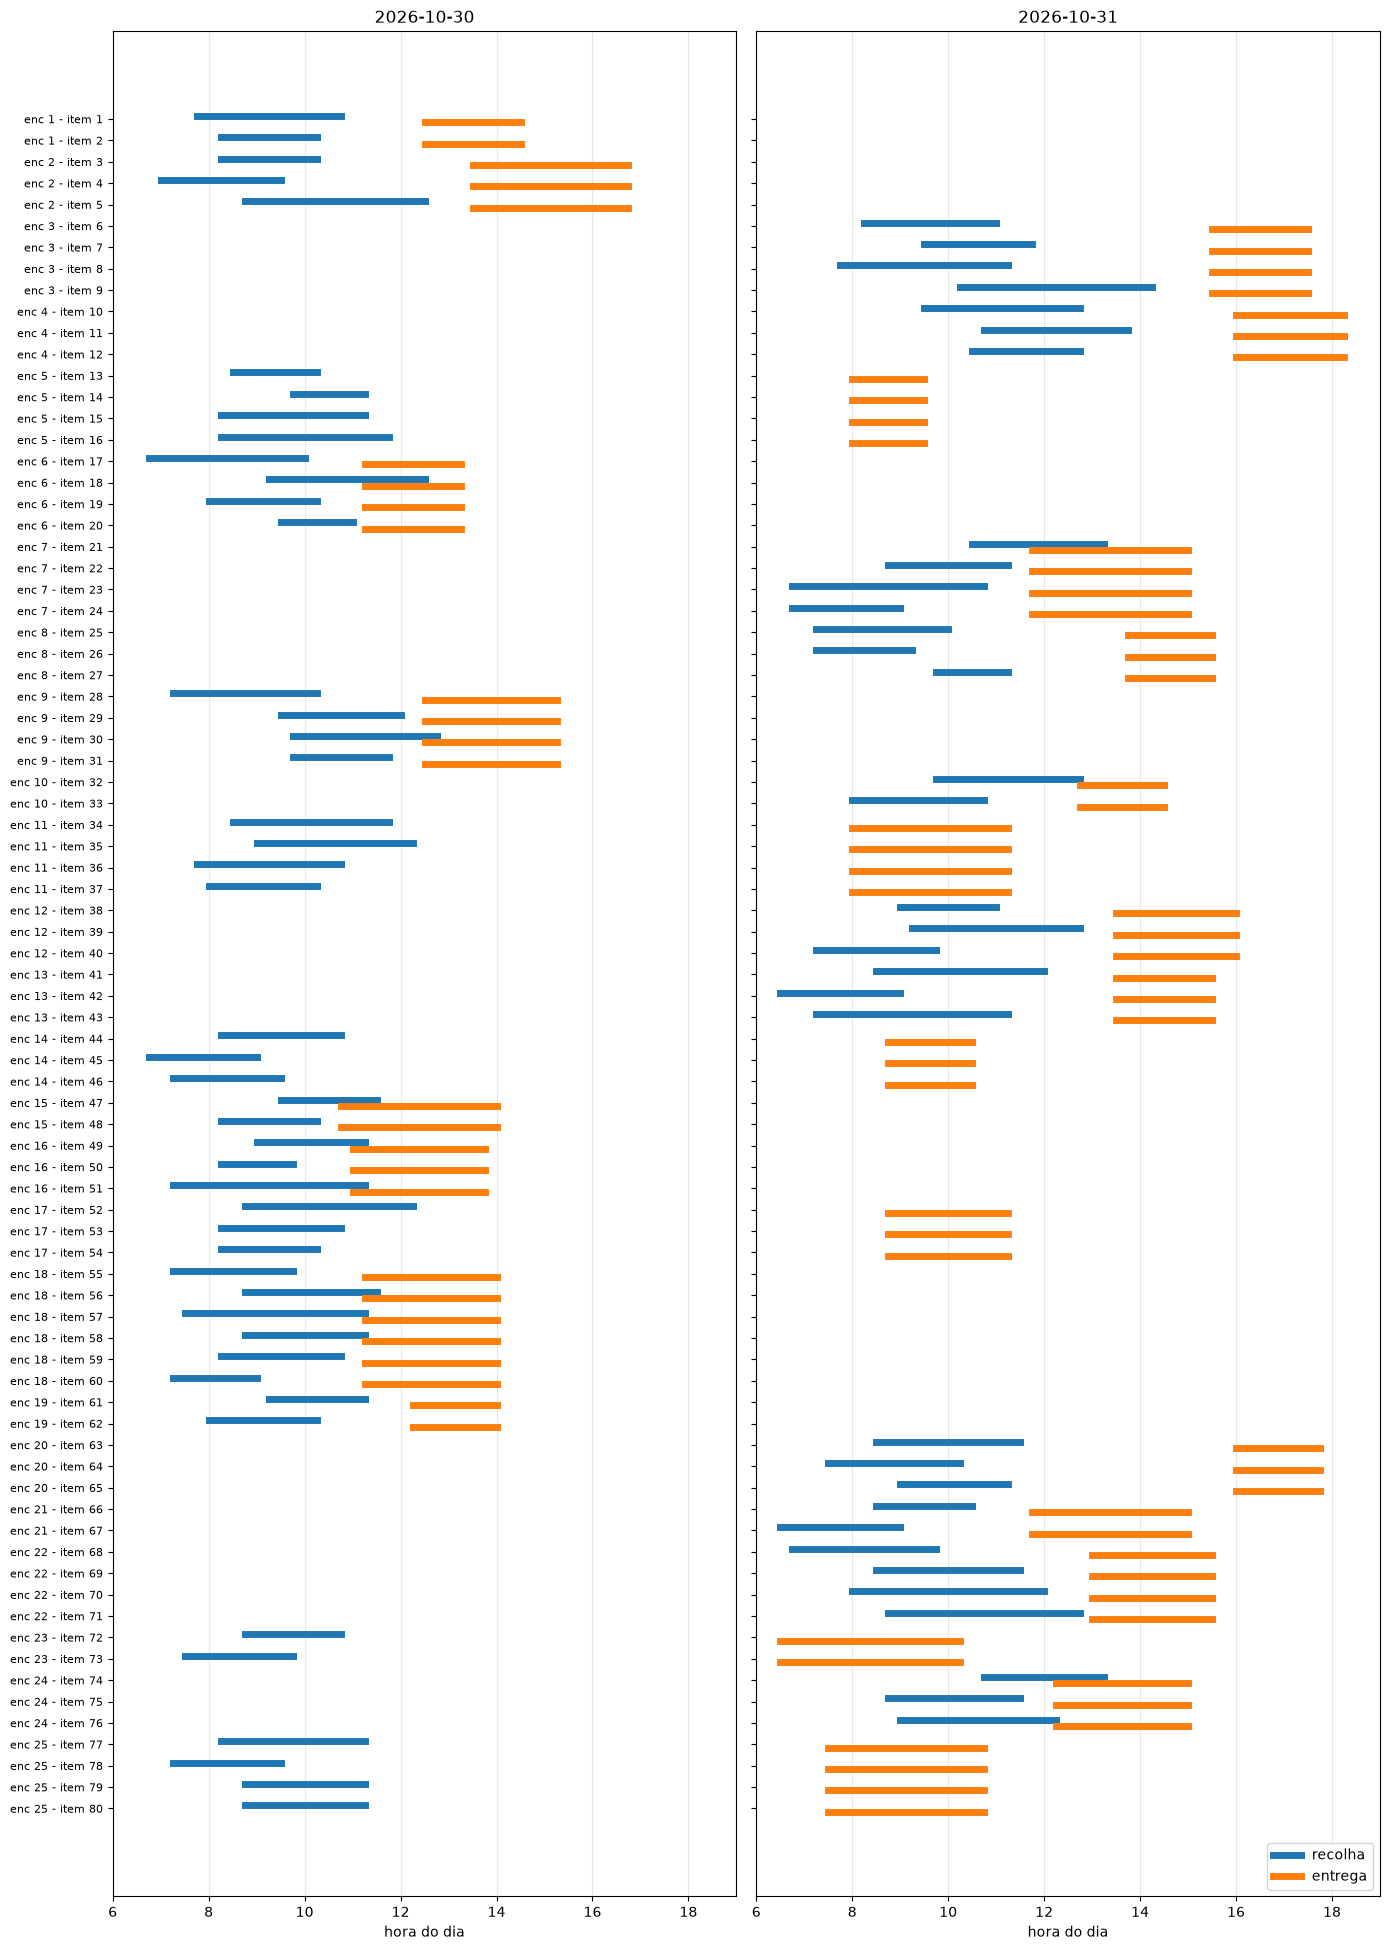

In [27]:
# hora_decimal converte uma data em número: 09:45 -> 9.75
dias = sorted(pedidos["dia_entrega"].unique())
altura = 2 + 0.22 * len(pedidos)                             # mais itens -> gráfico mais alto
hora_inicio = int(pedidos["availability_start"].dt.hour.min())          # hora mais cedo de todas as janelas
hora_fim = int(pedidos["delivery_end"].dt.hour.max()) + 1               # hora mais tarde de todas as janelas
fig, eixos = plt.subplots(1, len(dias), figsize=(14, altura), sharey=True)

for eixo, dia in zip(eixos, dias):
    for posicao, item in pedidos.iterrows():
        if item["dia_recolha"] == dia:
            eixo.plot([hora_decimal(item["availability_start"]), hora_decimal(item["availability_end"])],
                      [posicao - 0.15, posicao - 0.15], color="tab:blue", linewidth=5)
        if item["dia_entrega"] == dia:
            eixo.plot([hora_decimal(item["delivery_start"]), hora_decimal(item["delivery_end"])],
                      [posicao + 0.15, posicao + 0.15], color="tab:orange", linewidth=5)
    eixo.set_title(str(dia))
    eixo.set_xlabel("hora do dia")
    eixo.set_xlim(hora_inicio, hora_fim)
    eixo.grid(axis="x", alpha=0.3)

eixos[0].set_yticks(range(len(pedidos)))
eixos[0].set_yticklabels([f"enc {o} - item {i}" for o, i in zip(pedidos["order_id"], pedidos["order_item_id"])], fontsize=8)
eixos[0].invert_yaxis()
eixos[1].plot([], [], color="tab:blue", linewidth=5, label="recolha")
eixos[1].plot([], [], color="tab:orange", linewidth=5, label="entrega")
eixos[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

**Observações:**
- Todas as janelas são válidas. As de recolha duram entre 1h30 e 4h e as de entrega entre 1h30 e 3h45.
- As recolhas acontecem de manhã e no início da tarde (a última janela fecha às 14:15). As entregas vão das 06:30 às 18:15.
- Em 8 itens a janela de entrega abre antes de a de recolha fechar: para os entregar a tempo é preciso recolhê-los cedo.
- 20 itens (encomendas 5, 11, 14, 17, 23 e 25) são recolhidos no dia 30 e entregues no dia 31, ficando a noite no armazém.
- O dia 31 concentra o trabalho de entrega: 54 dos 80 itens são entregues nesse dia.

### 1.10 Distâncias entre paragens

**Objetivo:** confirmar que a matriz de distâncias está completa e coerente.

Verificamos se existem todos os pares de paragens, se a distância de A a B é igual à de B a A (**simetria**) e se ir de A a C diretamente nunca é mais longo do que passar por B (**desigualdade triangular**). Esta última propriedade será usada para justificar as heurísticas da pesquisa informada.

In [28]:
def matriz_paragens(dados, coluna):
    """
    Devolve uma tabela origem x destino com os valores de `coluna`
    ("distance_km" ou "duration_min"). A diagonal (de uma paragem para si própria) é 0.
    """
    matriz = dados["distance_matrix"].pivot(index="origin_location_id",
                                            columns="destination_location_id",
                                            values=coluna)
    return matriz.fillna(0)

In [29]:
n = len(locations)
print("Pares esperados:", n * (n - 1), "| pares na matriz:", len(distance_matrix))

# tabelas origem x destino, com 0 na diagonal
km = matriz_paragens(dados, "distance_km")
minutos = matriz_paragens(dados, "duration_min")

print("Matriz simétrica:", (km - km.T).abs().max().max() < 0.01)

Pares esperados: 182 | pares na matriz: 182
Matriz simétrica: True


In [30]:
# desigualdade triangular: km(a, c) <= km(a, b) + km(b, c) para todas as paragens
violacoes = 0
for a in km.index:
    for b in km.index:
        for c in km.index:
            if km.loc[a, c] > km.loc[a, b] + km.loc[b, c] + 0.02:   # tolerância: as distâncias estão arredondadas a 0,01 km
                violacoes += 1
print("Violações da desigualdade triangular:", violacoes)

Violações da desigualdade triangular: 0


In [31]:
print("Distância mínima:", distance_matrix["distance_km"].min(), "km")
print("Distância média: ", round(distance_matrix["distance_km"].mean(), 1), "km")
print("Distância máxima:", distance_matrix["distance_km"].max(), "km")

# velocidade usada para calcular os tempos (ignora pares com distância 0)
com_distancia = distance_matrix[distance_matrix["duration_min"] > 0]
velocidade = com_distancia["distance_km"] / (com_distancia["duration_min"] / 60)
print("Velocidade implícita:", round(velocidade.mean()), "km/h | velocidade dos veículos:", vehicles["avg_speed_kmh"].tolist())

Distância mínima: 0.0 km
Distância média:  30.4 km
Distância máxima: 91.13 km
Velocidade implícita: 45 km/h | velocidade dos veículos: [45.0, 45.0]


In [32]:
# pares de paragens com distância zero
distance_matrix[distance_matrix["distance_km"] == 0]

,origin_location_id,origin_type,destination_location_id,destination_type,distance_km,duration_min
44,4,producer,7,collection_center,0.0,0.0
81,7,collection_center,4,producer,0.0,0.0
102,8,delivery_location,13,delivery_location,0.0,0.0
163,13,delivery_location,8,delivery_location,0.0,0.0


Para cada paragem calculamos a distância ao armazém e qual é a paragem mais próxima. Esta informação será útil para as heurísticas da pesquisa informada.

In [33]:
nomes = locations.set_index("location_id")["name"]
linhas = []
for paragem in km.index:
    outras = km.loc[paragem].drop(paragem)                    # distâncias para as outras paragens
    mais_proxima = outras.idxmin()
    linhas.append({"paragem": paragem, "nome": nomes[paragem],
                   "km ao armazém": km.loc[paragem, ARMAZEM],
                   "paragem mais próxima": f"{mais_proxima} {nomes[mais_proxima]}",
                   "km à mais próxima": outras.min()})
proximidade = pd.DataFrame(linhas).set_index("paragem")
proximidade

,nome,km ao armazém,paragem mais próxima,km à mais próxima
paragem,,,,
1,Hortas Valente,30.60,6 Campos Oliveira,14.86
2,Campos Leite,37.66,14 Casa 7,15.48
3,Horta Morais,29.06,10 Restaurante 3,11.90
4,Courela Carvalho,0.00,7 Centro de Recolha 1,0.00
5,Horta Antunes,38.88,11 Loja 4,35.70
6,Campos Oliveira,23.53,1 Hortas Valente,14.86
7,Centro de Recolha 1,0.00,4 Courela Carvalho,0.00
8,Casa 1,14.30,13 Loja 6,0.00
9,Restaurante 2,20.22,14 Casa 7,2.07


**Observações:**
- A matriz está completa (182 pares para 14 paragens) e é simétrica.
- Não há violações da desigualdade triangular com uma tolerância de 0,02 km. Sem tolerância, haveria 4 casos com um excesso de apenas 0,01 km, no percurso Horta Morais (3) → armazém → Loja 4 (11), em que as três paragens estão praticamente em linha reta. Resultam do arredondamento das distâncias a duas casas decimais e não têm impacto prático.
- As distâncias variam entre 0 e 91,1 km. Os tempos foram calculados a 45 km/h, a mesma velocidade dos veículos.
- **O produtor 4 (Courela Carvalho) está no mesmo local do armazém** (distância 0): as suas 10 recolhas (80,9 kg) não exigem viagem. As paragens 8 (Casa 1) e 13 (Loja 6) também estão no mesmo local.
- A paragem mais afastada do armazém é o Restaurante 5 (52,3 km). O produtor Horta Antunes está isolado: a paragem mais próxima fica a 35,7 km.

### 1.11 Carga e capacidade dos veículos

**Objetivo:** comparar o peso a transportar com a capacidade dos veículos.

Como todos os produtos passam pelo armazém, separamos a carga das viagens de **recolha** (produtores → armazém) da carga das viagens de **entrega** (armazém → clientes).

In [34]:
carga = pd.DataFrame({
    "recolhas_kg": pedidos.groupby("dia_recolha")["weight_kg"].sum(),
    "entregas_kg": pedidos.groupby("dia_entrega")["weight_kg"].sum(),
}).rename_axis("dia")
carga

,recolhas_kg,entregas_kg
dia,,
2026-10-30,338.7,182.6
2026-10-31,241.3,397.4


In [35]:
print("Peso total:", pedidos["weight_kg"].sum(), "kg")
print("Capacidade dos veículos:", vehicles["capacity_kg"].tolist(), "kg | total:", vehicles["capacity_kg"].sum(), "kg")
print("Maior encomenda:", round(encomendas["peso_kg"].max(), 1), "kg")
print("Capacidade do armazém:", collection_centers["capacity_kg"].iloc[0], "kg")

Peso total: 580.0 kg
Capacidade dos veículos: [250.0, 300.0] kg | total: 550.0 kg
Maior encomenda: 38.4 kg
Capacidade do armazém: 5000.0 kg


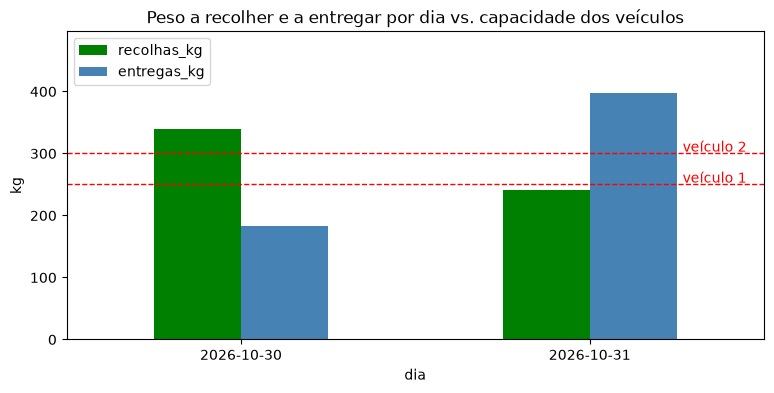

In [36]:
carga.plot.bar(figsize=(9, 4), rot=0, color=["green", "steelblue"])
for _, veiculo in vehicles.iterrows():
    plt.axhline(veiculo["capacity_kg"], color="red", linestyle="--", linewidth=1)
    plt.text(len(carga) - 0.55, veiculo["capacity_kg"] + 3, f"veículo {veiculo['vehicle_id']}", color="red", ha="right")
plt.ylim(0, 1.25 * max(carga.max().max(), vehicles["capacity_kg"].max()))   # espaço acima da barra mais alta
plt.title("Peso a recolher e a entregar por dia vs. capacidade dos veículos")
plt.ylabel("kg")
plt.legend(loc="upper left")
plt.show()

**Observações:**
- No total há 580 kg para uma frota de 550 kg (250 + 300 kg): **o peso total é superior à capacidade da frota**.
- No dia 30 há **338,7 kg para recolher** e no dia 31 há **397,4 kg para entregar**. Em ambos os casos, nenhum veículo consegue fazer o trabalho sozinho numa só viagem.
- **A capacidade é uma restrição determinante**: os dois veículos terão de partilhar a carga e fazer várias viagens ao armazém.
- A maior encomenda (38,4 kg) cabe em qualquer veículo, e o armazém (5000 kg) nunca é limitante.

### 1.12 Viabilidade dos pedidos

**Objetivo:** verificar se cada pedido pode ser cumprido, pelo menos isoladamente, respeitando as regras.

Os cálculos são feitos pelas funções `calcular_folgas` e `calcular_permanencias`, definidas abaixo. Ambas usam a função `tempo_viagem`, que lê da matriz os minutos de viagem entre duas paragens.

**Itens entregues no próprio dia.** Consideramos o melhor caso: o veículo recolhe o produto assim que fica disponível e segue sem desvios pelo percurso produtor → armazém → cliente. Somamos todos os tempos e calculamos a **folga**, isto é, quanto tempo sobra entre a chegada ao cliente e o fecho da janela de entrega. Uma folga negativa significaria que o pedido é impossível.

Para medir o custo da passagem obrigatória pelo armazém, calculamos também a folga se o produto fosse levado **diretamente** do produtor ao cliente.

In [37]:
def tempo_viagem(minutos, origem, destino):
    """Minutos de viagem entre duas paragens, lidos da matriz de tempos."""
    return minutos.loc[origem, destino]


def calcular_folgas(pedidos, minutos, armazem, tempo_servico, tempo_armazem):
    """
    Para os itens recolhidos e entregues no mesmo dia, calcula a folga no melhor caso:
    o veículo recolhe assim que o produto fica disponível e segue sem desvios.
    Folga = fecho da janela de entrega - hora de chegada (em minutos).
    São calculados dois percursos:
      - direto:       produtor -> cliente (sem as regras, apenas para comparação);
      - com armazém:  produtor -> armazém -> cliente (o percurso obrigatório).
    """
    linhas = []
    for _, item in pedidos.iterrows():
        if item["dia_recolha"] == item["dia_entrega"]:
            duracao = (tempo_servico                                                # recolha no produtor
                       + tempo_viagem(minutos, item["paragem_recolha"], armazem)    # viagem até ao armazém
                       + 2 * tempo_armazem                                           # descarregar + carregar
                       + tempo_viagem(minutos, armazem, item["paragem_entrega"]))   # viagem até ao cliente
            chegada = item["availability_start"] + pd.Timedelta(minutes=duracao)
            folga = (item["delivery_end"] - chegada).total_seconds() / 60

            # comparação: ir diretamente do produtor ao cliente, sem passar pelo armazém
            duracao_direta = tempo_viagem(minutos, item["paragem_recolha"], item["paragem_entrega"])
            chegada_direta = item["availability_start"] + pd.Timedelta(minutes=duracao_direta)
            folga_direta = (item["delivery_end"] - chegada_direta).total_seconds() / 60

            linhas.append({"item": item["order_item_id"], "duracao_min": round(duracao, 1),
                           "chegada": chegada.round("min"), "fecho_entrega": item["delivery_end"],
                           "folga_direta_min": round(folga_direta, 1), "folga_min": round(folga, 1)})
    return pd.DataFrame(linhas).sort_values("folga_min")

In [38]:
# duração = 10 min de recolha + viagem ao armazém + 15 + 15 min no armazém + viagem ao cliente
folgas = calcular_folgas(pedidos, minutos, ARMAZEM, TEMPO_SERVICO, TEMPO_ARMAZEM)
print("Itens analisados:", len(folgas))
print("Impossíveis indo direto:       ", (folgas["folga_direta_min"] < 0).sum())
print("Impossíveis passando no armazém:", (folgas["folga_min"] < 0).sum())
print("Folga perdida, em média, por passar no armazém:",
      round((folgas["folga_direta_min"] - folgas["folga_min"]).mean()), "min")
folgas.head()

Itens analisados: 60
Impossíveis indo direto:        0
Impossíveis passando no armazém: 0
Folga perdida, em média, por passar no armazém: 65 min


,item,duracao_min,chegada,fecho_entrega,folga_direta_min,folga_min
15,20,114.4,2026-10-30 11:24:00,2026-10-30 13:15:00,192.8,110.6
13,18,114.4,2026-10-30 11:09:00,2026-10-30 13:15:00,207.8,125.6
57,74,110.9,2026-10-31 12:36:00,2026-10-31 15:00:00,189.7,144.1
16,21,110.9,2026-10-31 12:21:00,2026-10-31 15:00:00,204.7,159.1
35,47,109.3,2026-10-30 11:19:00,2026-10-30 14:00:00,235.0,160.7


**Itens entregues no dia seguinte.** Estes produtos passam a noite no armazém e não podem ficar lá mais de 24 h (desde que chegam até começarem a ser carregados). Calculamos a permanência:
- **mínima** — recolher o mais tarde possível e carregar apenas a tempo de chegar quando a janela de entrega abre;
- **máxima** — recolher o mais cedo possível e carregar o mais tarde possível.

In [39]:
def calcular_permanencias(pedidos, minutos, armazem, tempo_servico, tempo_armazem):
    """
    Para os itens entregues no dia seguinte, calcula quanto tempo (em horas) podem
    ficar no armazém, entre a chegada e o início do carregamento:
      - mínima: recolher o mais tarde possível e carregar só a tempo da abertura da entrega;
      - máxima: recolher o mais cedo possível e carregar o mais tarde possível.
    """
    linhas = []
    for _, item in pedidos.iterrows():
        if item["dia_recolha"] != item["dia_entrega"]:
            ida = tempo_servico + tempo_viagem(minutos, item["paragem_recolha"], armazem)    # recolha + viagem
            volta = tempo_armazem + tempo_viagem(minutos, armazem, item["paragem_entrega"])  # carregar + viagem

            chega_cedo = item["availability_start"] + pd.Timedelta(minutes=ida)
            chega_tarde = item["availability_end"] + pd.Timedelta(minutes=ida)
            carrega_cedo = item["delivery_start"] - pd.Timedelta(minutes=volta)
            carrega_tarde = item["delivery_end"] - pd.Timedelta(minutes=volta)

            minima = (carrega_cedo - chega_tarde).total_seconds() / 3600
            maxima = (carrega_tarde - chega_cedo).total_seconds() / 3600
            linhas.append({"item": item["order_item_id"], "encomenda": item["order_id"],
                           "permanencia_min_h": round(minima, 2), "permanencia_max_h": round(maxima, 2)})
    return pd.DataFrame(linhas)

In [40]:
permanencias = calcular_permanencias(pedidos, minutos, ARMAZEM, TEMPO_SERVICO, TEMPO_ARMAZEM)
print("Itens impossíveis (mínima > 24 h):", (permanencias["permanencia_min_h"] > PERMANENCIA_MAX).sum())
print("Itens com horários proibidos (máxima > 24 h):", (permanencias["permanencia_max_h"] > PERMANENCIA_MAX).sum())
permanencias

Itens impossíveis (mínima > 24 h): 0
Itens com horários proibidos (máxima > 24 h): 15


,item,encomenda,permanencia_min_h,permanencia_max_h
0,13,5,20.20,23.45
1,14,5,19.02,22.02
2,15,5,19.36,23.86
3,16,5,18.70,23.70
4,34,11,18.71,25.21
5,35,11,18.03,24.53
6,36,11,19.87,26.12
7,37,11,20.25,25.75
8,44,14,20.50,24.75
9,45,14,22.89,26.89


**Observações:**
- Os 60 itens entregues no próprio dia são todos exequíveis: mesmo passando pelo armazém, têm no mínimo 111 min de folga (item 20).
- A passagem obrigatória pelo armazém retira, em média, 65 min de folga a cada item, mas não torna nenhum pedido impossível.
- Os 20 itens entregues no dia seguinte também são exequíveis, porque a permanência mínima é sempre inferior a 24 h.
- Em 15 desses 20 itens a permanência máxima ultrapassa as 24 h: tal como no *tiny*, o limite de 24 h é uma restrição ativa que terá de ser modelada no CSP.

### 1.13 Comparação com o conjunto *tiny*

**Objetivo:** comparar a dimensão deste conjunto com a do conjunto *tiny*.

In [41]:
# a mesma função de leitura serve para os dois conjuntos de dados
tiny = carregar_dados("docs/data_tiny/")
small = carregar_dados("docs/data_small_30_31oct2026/")

comparacao = pd.DataFrame({
    "tiny":  [len(tiny["locations"]), len(tiny["orders"]), len(tiny["order_items"]),
              round(tiny["order_items"]["weight_kg"].sum(), 1), tiny["vehicles"]["capacity_kg"].sum()],
    "small": [len(small["locations"]), len(small["orders"]), len(small["order_items"]),
              round(small["order_items"]["weight_kg"].sum(), 1), small["vehicles"]["capacity_kg"].sum()],
}, index=["paragens", "encomendas", "itens", "peso total (kg)", "capacidade da frota (kg)"], dtype=object)
comparacao

,tiny,small
paragens,9,14
encomendas,12,25
itens,40,80
peso total (kg),270.0,580.0
capacidade da frota (kg),350.0,550.0


**Observações:** o conjunto *small* tem mais do dobro das encomendas e o dobro dos itens do *tiny*, e 14 paragens em vez de 9. Enquanto no *tiny* o peso total (270 kg) cabe na frota (350 kg), no *small* o peso total (580 kg) é superior à capacidade da frota (550 kg).

### 1.14 Conclusões da EDA

1. **Os dados estão corretos.** Foram lidos sem erros e não têm valores em falta, repetidos ou referências inválidas. Ficam em memória em dicionários e listas do Python, prontos para os algoritmos.
2. **O problema é cerca de duas vezes maior do que o *tiny***: 14 paragens, 25 encomendas e 80 itens (580 kg) em 2 dias, com 2 veículos. O UCS, que serve para validar o ótimo no *tiny*, deverá tornar-se demasiado lento aqui, o que reforça a importância das heurísticas.
3. **O armazém é um ponto obrigatório.** Cada encomenda junta produtos de 2 a 5 produtores e é entregue de uma só vez. A passagem pelo armazém custa, em média, 65 min de folga por item.
4. **A capacidade é determinante.** O peso total ultrapassa a capacidade da frota, e as recolhas do dia 30 (338,7 kg) e as entregas do dia 31 (397,4 kg) excedem a capacidade de qualquer veículo: são obrigatórias várias viagens.
5. **As janelas temporais e o limite de 24 h no armazém são restrições ativas.** Todos os pedidos são exequíveis, mas em 15 dos 20 itens que passam a noite no armazém algumas combinações de horários não são permitidas.
6. **Particularidades da geografia:** o produtor 4 está no mesmo local do armazém e as paragens 8 e 13 coincidem, o que reduz o número real de paragens distintas. A matriz respeita a desigualdade triangular (a menos de arredondamentos de 0,01 km), o que permite heurísticas admissíveis para o A\*.
7. **Ponto a confirmar:** o veículo 1 é refrigerado, mas nenhum produto indica precisar de frio. Assumimos que ambos os veículos podem transportar qualquer produto.